[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L1/BA_L1_eth_supply/BA_L1_eth_supply.ipynb)

# BA_L1_eth_supply: Ether Supply and Proof of Stake

*Quantlet of Lecture 1, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Ether in circulation and new Ether per day, January 2019 to 23 May 2026, around the Merge of 15 September 2022, when Ethereum replaced proof of work with proof of stake; supply growth and issuance before and after.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts


def load_onchain(name):
    # daily on-chain series, one column per coin, as numbers (missing values are NaN)
    return onchain(name).apply(pd.to_numeric, errors='coerce')


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))

## Data and method

`SplyCur` is the Ether in circulation and `IssTotNtv` the Ether created per day, both from Coin Metrics community
data, which end on 23 May 2026. The growth rate of the supply between two dates is annualised as
$(S_b / S_a)^{365.25 / n} - 1$, with $n$ the number of days.

**How to read the chart.** Left: the supply rises steadily until the Merge and is almost flat after it; since
August 2021 a part of every fee is destroyed, which can make the supply fall. Right: new Ether per day drops at the
Merge, because validators are paid less than miners were.

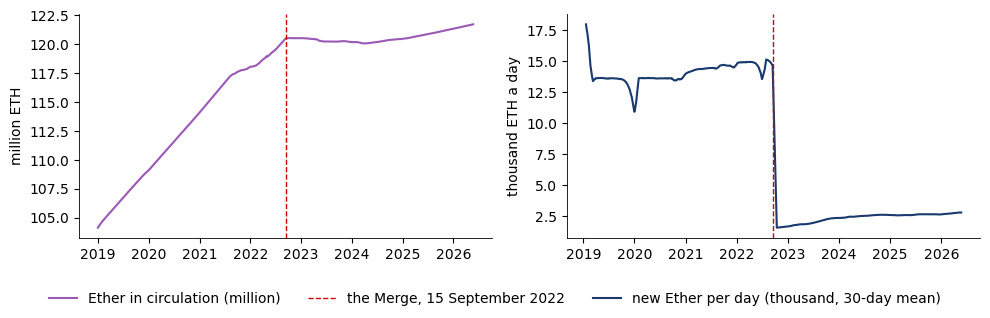

Ether in circulation: 120.52 million at the Merge, 121.72 million on 23 May 2026
Supply growth a year: 3.45% in the two years before the Merge, 0.27% since
New Ether per day: 14,703 in the year before the Merge, 1,856 in the year after
Lowest supply since the Merge: 120.07 million (04 April 2024)


In [5]:
# Ether: coins in circulation and new coins per day (Coin Metrics community data), around the Merge of 15 September 2022
es = pd.read_csv(data_file('indices', 'eth_supply_coinmetrics.csv'), parse_dates=['date']).set_index('date').loc['2019':]
MERGE = pd.Timestamp('2022-09-15')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(es.index, es['SplyCur'] / 1e6, color=ETH, label='Ether in circulation (million)')
ax[0].set_ylabel('million ETH')
ax[1].plot(es.index, es['IssTotNtv'].rolling(30, min_periods=20).mean() / 1e3, color=BLUE, label='new Ether per day (thousand, 30-day mean)')
ax[1].set_ylabel('thousand ETH a day')
for a in ax:
    a.axvline(MERGE, color=RED, lw=1, ls='--')
ax[0].plot([], [], color=RED, lw=1, ls='--', label='the Merge, 15 September 2022')
legend_below(fig, ncol=3, bottom=0.12)
save_fig(fig, 'ba_l1_eth_supply')


def growth(a, b):
    a, b = pd.Timestamp(a), pd.Timestamp(b)
    return 100 * ((es.loc[b, 'SplyCur'] / es.loc[a, 'SplyCur']) ** (365.25 / (b - a).days) - 1)


end = es.index[-1]
print(f'Ether in circulation: {es.loc[MERGE, "SplyCur"] / 1e6:.2f} million at the Merge, {es["SplyCur"].iloc[-1] / 1e6:.2f} million on {end:%d %B %Y}')
print(f'Supply growth a year: {growth("2020-09-15", MERGE):.2f}% in the two years before the Merge, {growth(MERGE, end):.2f}% since')
print(f'New Ether per day: {es.loc["2021-09-15":"2022-09-14", "IssTotNtv"].mean():,.0f} in the year before the Merge, '
      f'{es.loc["2022-09-16":"2023-09-15", "IssTotNtv"].mean():,.0f} in the year after')
low = es.loc[MERGE:, 'SplyCur']
print(f'Lowest supply since the Merge: {low.min() / 1e6:.2f} million ({low.idxmin():%d %B %Y})')